# Retail Stockout Prediction with XGBoost

**Goal:** Forecast whether an existing store-product series will have a recorded stockout on the next day.

**Data:** [FreshRetailNet-50K](https://huggingface.co/datasets/Dingdong-Inc/FreshRetailNet-50K) by Dingdong-Inc (CC BY 4.0). The notebook uses a 10% training subset and the matching store-product series from the official future evaluation split.

**Evaluation:** Chronological validation, persistence baseline, and rolling next-day out-of-time assessment. Results are reported alongside precision-recall tradeoffs and limitations.

> The numerical results shown below are saved outputs from the original Colab run. Re-run this cleaned notebook from the top to verify them in a fresh environment before publishing.

## 1. Environment and dependencies

The analysis requires **NumPy, pandas, scikit-learn, XGBoost, Matplotlib, Hugging Face Datasets, and PyArrow**. This setup cell installs dependency ranges matching `requirements.txt` so the notebook can run in Google Colab without accessing a personal Google Drive. For local use, run `pip install -r requirements.txt` instead. Dependency ranges permit version updates; for exact reproducibility, record the tested package versions.

In [ ]:
# Colab setup: dependencies matching the repository's requirements.txt
%pip -q install "numpy>=1.24,<3" "pandas>=2.0,<3" "scikit-learn>=1.3,<2" "xgboost>=2.0,<4" "matplotlib>=3.7,<4" "datasets>=3.0,<5" "pyarrow>=15,<24"

## 2. Load the FreshRetailNet-50K training subset

Download the first **10% of the official training split** from Dingdong-Inc's FreshRetailNet-50K dataset and convert it to a pandas DataFrame. Dates are parsed for chronological feature engineering. The initial inspection reports **450,000 daily observations**, covering **March 28–June 25, 2024**, with **44.28%** of rows recording at least one stockout hour. This is a selected subset, not a random sample of all stores and products.

In [4]:
from datasets import load_dataset
import pandas as pd

dataset = load_dataset(
    "Dingdong-Inc/FreshRetailNet-50K",
    split="train[:10%]"
)

df = dataset.to_pandas()
df["dt"] = pd.to_datetime(df["dt"])

print("Dataset shape:", df.shape)
print("Date range:", df["dt"].min(), df["dt"].max())
print("Stockout rate:",
      (df["stock_hour6_22_cnt"] > 0).mean().round(4))

display(df.head())

Dataset shape: (450000, 19)
Date range: 2024-03-28 00:00:00 2024-06-25 00:00:00
Stockout rate: 0.4428


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
0,0,0,0,5,6,65,38,2024-03-28,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,1.6999,15.48,73.54,1.97
1,0,0,0,5,6,65,38,2024-03-29,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,3.0190,15.08,76.56,1.71
2,0,0,0,5,6,65,38,2024-03-30,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,2.0942,15.91,76.47,1.73
3,0,0,0,5,6,65,38,2024-03-31,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",11,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...",1.0,1,0,1.5618,16.13,77.40,1.76
4,0,0,0,5,6,65,38,2024-04-01,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",8,"[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",1.0,0,0,3.5386,15.37,78.26,1.25


## 3. Audit coverage, completeness, and target prevalence

Check the number of distinct stores, products, and store-product time series; confirm that each series has the same number of daily observations and that no fields are missing. The selected subset contains **57 stores, 352 distinct product IDs, and 5,000 store-product series**, each with **90 daily records**. The observed stockout class is fairly common, so accuracy alone is not a sufficient evaluation metric.

In [5]:
print("Unique stores:", df["store_id"].nunique())
print("Unique products:", df["product_id"].nunique())

print("Store-product combinations:",
      df.groupby(["store_id", "product_id"]).ngroups)

print("\nRecords per combination:")
print(
    df.groupby(["store_id", "product_id"])
      .size()
      .describe()
)

print("\nMissing values:")
print(df.isna().sum())

print("\nStockout distribution:")
print(
    (df["stock_hour6_22_cnt"] > 0)
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Unique stores: 57
Unique products: 352
Store-product combinations: 5000

Records per combination:
count    5000.0
mean       90.0
std         0.0
min        90.0
25%        90.0
50%        90.0
75%        90.0
max        90.0
dtype: float64

Missing values:
city_id                0
store_id               0
management_group_id    0
first_category_id      0
second_category_id     0
third_category_id      0
product_id             0
dt                     0
sale_amount            0
hours_sale             0
stock_hour6_22_cnt     0
hours_stock_status     0
discount               0
holiday_flag           0
activity_flag          0
precpt                 0
avg_temperature        0
avg_humidity           0
avg_wind_level         0
dtype: int64

Stockout distribution:
stock_hour6_22_cnt
False    55.72
True     44.28
Name: proportion, dtype: float64


## 4. Build lagged features, train XGBoost, and assess an internal future period

Define a stockout event as `stock_hour6_22_cnt > 0` and shift the outcome **one day ahead within each store-product series**. Construct historical sales, previous-day stockout indicators, rolling summaries, store/product attributes, and calendar features. Split the data **chronologically** into training, validation, and internal test periods. Train XGBoost, select a decision threshold **on validation data**, and compare the later-period predictions with a **persistence baseline** (tomorrow equals today). At threshold **0.30**, the saved internal-test result is **84.31% recall, 49.24% precision, and 62.17% F1**. Forecasts assume that each day's sales and stockout data are available before the next day begins. Identifiers and derived features describe existing store-product combinations, not previously unseen ones.

In [6]:

import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score
)

# 1. Prepare data
data = df.copy()
data["dt"] = pd.to_datetime(data["dt"])
data = data.sort_values(
    ["store_id", "product_id", "dt"]
).reset_index(drop=True)

groups = data.groupby(["store_id", "product_id"])

# Actual observed stockout today
data["stockout_today"] = (
    data["stock_hour6_22_cnt"] > 0
).astype(int)

# Target: stockout TOMORROW
data["target"] = groups["stockout_today"].shift(-1)

# 2. Historical features, all known by end of today
data["sales_today"] = data["sale_amount"]
data["stockout_hours_today"] = data["stock_hour6_22_cnt"]

for lag in [1, 2, 3, 7]:
    data[f"sales_lag_{lag}"] = (
        groups["sale_amount"].shift(lag)
    )
    data[f"stockout_lag_{lag}"] = (
        groups["stockout_today"].shift(lag)
    )

for window in [3, 7]:
    data[f"sales_avg_{window}d"] = (
        data.groupby(["store_id", "product_id"])["sale_amount"]
        .transform(lambda s: s.rolling(window).mean())
    )
    data[f"stockout_rate_{window}d"] = (
        data.groupby(["store_id", "product_id"])["stockout_today"]
        .transform(lambda s: s.rolling(window).mean())
    )

# Calendar information for tomorrow is known
data["tomorrow_dayofweek"] = (
    data["dt"] + pd.Timedelta(days=1)
).dt.dayofweek

data["tomorrow_month"] = (
    data["dt"] + pd.Timedelta(days=1)
).dt.month

features = [
    "store_id", "product_id",
    "first_category_id", "second_category_id",
    "third_category_id",
    "sales_today", "stockout_hours_today",
    "discount", "activity_flag",
    "sales_lag_1", "sales_lag_2",
    "sales_lag_3", "sales_lag_7",
    "stockout_lag_1", "stockout_lag_2",
    "stockout_lag_3", "stockout_lag_7",
    "sales_avg_3d", "sales_avg_7d",
    "stockout_rate_3d", "stockout_rate_7d",
    "tomorrow_dayofweek", "tomorrow_month"
]

data = data.dropna(subset=features + ["target"]).copy()
data["target"] = data["target"].astype(int)

# Treat identifiers as categories, not numerical quantities
categorical_cols = [
    "store_id", "product_id",
    "first_category_id", "second_category_id",
    "third_category_id"
]

for col in categorical_cols:
    data[col] = data[col].astype("category")

# 3. Chronological split: 60% train, 20% validation, 20% test
dates = np.sort(data["dt"].unique())
train_end = dates[int(len(dates) * 0.60)]
val_end = dates[int(len(dates) * 0.80)]

train = data[data["dt"] < train_end]
val = data[(data["dt"] >= train_end) & (data["dt"] < val_end)]
test = data[data["dt"] >= val_end]

X_train, y_train = train[features], train["target"]
X_val, y_val = val[features], val["target"]
X_test, y_test = test[features], test["target"]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# 4. Train XGBoost
model = XGBClassifier(
    n_estimators=250,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    enable_categorical=True,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# 5. Choose threshold using validation only
val_prob = model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.05)
val_f1 = [
    f1_score(y_val, val_prob >= t, zero_division=0)
    for t in thresholds
]

best_threshold = float(thresholds[np.argmax(val_f1)])
print("\nSelected validation threshold:", round(best_threshold, 3))

# 6. Final evaluation on untouched test period
test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

print("\nXGBOOST TEST RESULTS")
print(classification_report(y_test, test_pred, digits=4))
print("Confusion matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nPrecision:", round(precision_score(y_test, test_pred), 4))
print("Recall:", round(recall_score(y_test, test_pred), 4))
print("F1:", round(f1_score(y_test, test_pred), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print("Test stockout prevalence:", round(y_test.mean(), 4))

# 7. Simple persistence baseline
baseline_pred = test["stockout_today"].astype(int)

print("\nPERSISTENCE BASELINE")
print("Precision:", round(precision_score(y_test, baseline_pred), 4))
print("Recall:", round(recall_score(y_test, baseline_pred), 4))
print("F1:", round(f1_score(y_test, baseline_pred), 4))


Train: (245000, 23)
Validation: (80000, 23)
Test: (85000, 23)

Selected validation threshold: 0.3

XGBOOST TEST RESULTS
              precision    recall  f1-score   support

           0     0.7638    0.3685    0.4971     49234
           1     0.4924    0.8431    0.6217     35766

    accuracy                         0.5682     85000
   macro avg     0.6281    0.6058    0.5594     85000
weighted avg     0.6496    0.5682    0.5495     85000

Confusion matrix:
[[18141 31093]
 [ 5610 30156]]

Precision: 0.4924
Recall: 0.8431
F1: 0.6217
PR-AUC: 0.6075
ROC-AUC: 0.6848
Test stockout prevalence: 0.4208

PERSISTENCE BASELINE
Precision: 0.5825
Recall: 0.5802
F1: 0.5813


## 5. Inspect validation-set precision–recall tradeoffs

Calculate precision, recall, and F1 across candidate classification thresholds **using validation predictions only**. The saved output shows that a threshold near **0.523** attains about **60% validation precision** but only **41.2% recall**, whereas the F1-oriented threshold near **0.287** gives about **83.5% recall** with **45.8% precision**. The final reporting threshold remains the earlier validation-selected **0.30**. This comparison illustrates how a retailer's false-alarm tolerance affects the optimal operating point.

In [7]:

from sklearn.metrics import precision_recall_curve
import pandas as pd
import numpy as np

# Use validation data only to choose threshold
precision, recall, thresholds = precision_recall_curve(
    y_val, val_prob
)

results = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision[:-1],
    "recall": recall[:-1],
    "f1": (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-10)
    )
})

eligible = results[results["precision"] >= 0.60]

if len(eligible) > 0:
    selected = eligible.sort_values(
        "recall", ascending=False
    ).iloc[0]

    print("Threshold meeting >=60% validation precision:")
    print(selected.round(4))
else:
    print("No threshold achieves 60% precision on validation data.")

print("\nHighest-F1 validation thresholds:")
print(results.nlargest(10, "f1").round(4))


Threshold meeting >=60% validation precision:
threshold    0.5229
precision    0.6000
recall       0.4121
f1           0.4886
Name: 58383, dtype: float64

Highest-F1 validation thresholds:
       threshold  precision  recall      f1
23370     0.2866     0.4584  0.8345  0.5917
23373     0.2866     0.4584  0.8345  0.5917
23369     0.2866     0.4583  0.8345  0.5917
23372     0.2866     0.4584  0.8345  0.5917
23375     0.2866     0.4584  0.8344  0.5917
23368     0.2866     0.4583  0.8345  0.5917
23378     0.2866     0.4584  0.8344  0.5917
23371     0.2866     0.4583  0.8345  0.5917
23374     0.2866     0.4584  0.8344  0.5917
23367     0.2866     0.4583  0.8345  0.5917


## 6. Interpret the trained model with feature importance

Rank the model's built-in feature importance scores and visualize the 15 highest-ranked predictors. The strongest are **current-day stockout hours (35.67%)** and the **three-day stockout rate (21.38%)**, suggesting reliance on recent availability patterns. These are **model importance scores**, not causal effects; correlated rolling and lagged features may share importance. Current-day outcomes are legitimate only for an **end-of-day forecast of tomorrow**.

Top 15 most important features:


,Feature,Importance
6,stockout_hours_today,0.356721
19,stockout_rate_3d,0.213783
14,stockout_lag_2,0.056065
1,product_id,0.048520
20,stockout_rate_7d,0.047741
4,third_category_id,0.031803
22,tomorrow_month,0.030200
3,second_category_id,0.026406
2,first_category_id,0.025032
13,stockout_lag_1,0.023907


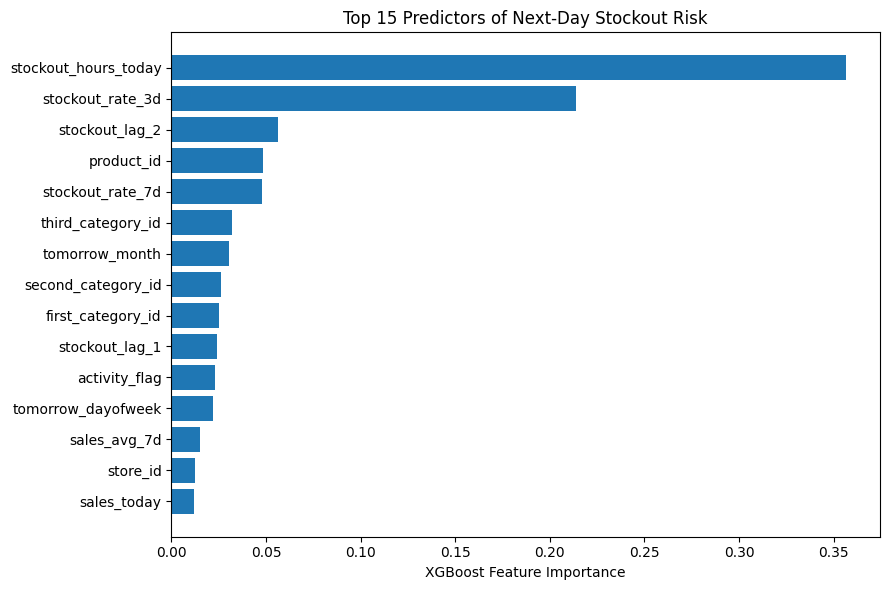

In [8]:

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 15 most important features:")
display(importance.head(15))

plt.figure(figsize=(9, 6))
plt.barh(
    importance.head(15)["Feature"][::-1],
    importance.head(15)["Importance"][::-1]
)
plt.xlabel("XGBoost Feature Importance")
plt.title("Top 15 Predictors of Next-Day Stockout Risk")
plt.tight_layout()
plt.show()


## 7. Load and inspect the official future evaluation period

Retrieve the dataset's separate `eval` split, covering **June 26–July 2, 2024**, and inspect overlap with the selected training series. The full evaluation split contains **350,000 records and 50,000 store-product series**; only **5,000 series** overlap with this experiment's training subset. The evaluation below is intentionally restricted to these previously observed series, so it **does not test new-store or new-product generalization**.

In [9]:

from datasets import load_dataset

eval_ds = load_dataset(
    "Dingdong-Inc/FreshRetailNet-50K",
    split="eval"
)

eval_df = eval_ds.to_pandas()
eval_df["dt"] = pd.to_datetime(eval_df["dt"])

train_pairs = set(
    zip(df["store_id"], df["product_id"])
)

eval_pairs = set(
    zip(eval_df["store_id"], eval_df["product_id"])
)

print("Evaluation shape:", eval_df.shape)
print("Evaluation date range:",
      eval_df["dt"].min(), eval_df["dt"].max())

print("Evaluation store-product pairs:", len(eval_pairs))
print("Overlapping store-product pairs:",
      len(train_pairs & eval_pairs))

print("Evaluation stockout prevalence:",
      round((eval_df["stock_hour6_22_cnt"] > 0).mean(), 4))


Evaluation shape: (350000, 19)
Evaluation date range: 2024-06-26 00:00:00 2024-07-02 00:00:00
Evaluation store-product pairs: 50000
Overlapping store-product pairs: 5000
Evaluation stockout prevalence: 0.4098


## 8. Verify chronological separation

Print the feature-date boundaries for the training (**April 4–May 22**), validation (**May 23–June 7**), and internal test (**June 8–24**) periods. The official evaluation begins **June 26**. Because the target is shifted forward one day, distinguish **feature dates** from **target dates** when checking time-based leakage. No data from the official evaluation period is used to fit the model.

In [10]:

print("Training feature dates:",
      train["dt"].min(), "to", train["dt"].max())

print("Validation feature dates:",
      val["dt"].min(), "to", val["dt"].max())

print("Internal test feature dates:",
      test["dt"].min(), "to", test["dt"].max())

print("Official evaluation starts:",
      eval_df["dt"].min())


Training feature dates: 2024-04-04 00:00:00 to 2024-05-22 00:00:00
Validation feature dates: 2024-05-23 00:00:00 to 2024-06-07 00:00:00
Internal test feature dates: 2024-06-08 00:00:00 to 2024-06-24 00:00:00
Official evaluation starts: 2024-06-26 00:00:00


## 9. Evaluate rolling next-day forecasts on future observations

Join the selected historical series to their official future records and recreate the **same feature transformations** used during training. The rows dated **June 25–July 1** predict outcomes dated **June 26–July 2**. On **35,000** future-period predictions, the saved results show **79.72% recall, 48.74% precision, 60.50% F1, 0.5517 PR-AUC, and 0.643 ROC-AUC**. Recall exceeds the persistence baseline (**55.74%**) by **23.98 percentage points**, but precision is lower (**48.74% versus 56.85%**) and there are **12,358 false positives**. This is a **rolling** evaluation: for each next-day prediction, the previous day's observations are assumed available; it is not a seven-day-ahead forecast issued on June 25. Results apply to this selected group of existing series and this specified horizon.

In [11]:

# Combine historical and evaluation observations
# to construct features consistently.
history = df.copy()
future = eval_df.copy()

history["dt"] = pd.to_datetime(history["dt"])
future["dt"] = pd.to_datetime(future["dt"])

# Keep the 5,000 store-product combinations used in training
future = future.merge(
    history[["store_id", "product_id"]].drop_duplicates(),
    on=["store_id", "product_id"],
    how="inner"
)

combined = pd.concat([history, future], ignore_index=True)
combined = combined.sort_values(
    ["store_id", "product_id", "dt"]
).reset_index(drop=True)

g = combined.groupby(["store_id", "product_id"])

combined["stockout_today"] = (
    combined["stock_hour6_22_cnt"] > 0
).astype(int)

combined["target"] = g["stockout_today"].shift(-1)

combined["sales_today"] = combined["sale_amount"]
combined["stockout_hours_today"] = combined["stock_hour6_22_cnt"]

for lag in [1, 2, 3, 7]:
    combined[f"sales_lag_{lag}"] = (
        g["sale_amount"].shift(lag)
    )
    combined[f"stockout_lag_{lag}"] = (
        g["stockout_today"].shift(lag)
    )

for window in [3, 7]:
    combined[f"sales_avg_{window}d"] = (
        combined.groupby(
            ["store_id", "product_id"]
        )["sale_amount"].transform(
            lambda s: s.rolling(window).mean()
        )
    )

    combined[f"stockout_rate_{window}d"] = (
        combined.groupby(
            ["store_id", "product_id"]
        )["stockout_today"].transform(
            lambda s: s.rolling(window).mean()
        )
    )

combined["tomorrow_dayofweek"] = (
    combined["dt"] + pd.Timedelta(days=1)
).dt.dayofweek

combined["tomorrow_month"] = (
    combined["dt"] + pd.Timedelta(days=1)
).dt.month

# Rows dated June 25–July 1 predict June 26–July 2.
official = combined[
    (combined["dt"] >= pd.Timestamp("2024-06-25")) &
    (combined["dt"] < pd.Timestamp("2024-07-02"))
].dropna(subset=features + ["target"]).copy()

for col in categorical_cols:
    official[col] = official[col].astype("category")

X_official = official[features]
y_official = official["target"].astype(int)

# Use the threshold selected on validation data
official_prob = model.predict_proba(X_official)[:, 1]
official_pred = (
    official_prob >= best_threshold
).astype(int)

print("Official evaluation samples:", len(official))
print("Threshold:", best_threshold)

print("\nOFFICIAL EVALUATION RESULTS")
print(classification_report(
    y_official, official_pred, digits=4
))

print("Confusion matrix:")
print(confusion_matrix(y_official, official_pred))

print("PR-AUC:",
      round(average_precision_score(
          y_official, official_prob
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          y_official, official_prob
      ), 4))

# Persistence baseline
baseline = official["stockout_today"].astype(int)

print("\nPERSISTENCE BASELINE")
print("Precision:", round(precision_score(y_official, baseline), 4))
print("Recall:", round(recall_score(y_official, baseline), 4))
print("F1:", round(f1_score(y_official, baseline), 4))


Official evaluation samples: 35000
Threshold: 0.30000000000000004

OFFICIAL EVALUATION RESULTS
              precision    recall  f1-score   support

           0     0.7255    0.3900    0.5073     20259
           1     0.4874    0.7972    0.6050     14741

    accuracy                         0.5615     35000
   macro avg     0.6065    0.5936    0.5561     35000
weighted avg     0.6252    0.5615    0.5484     35000

Confusion matrix:
[[ 7901 12358]
 [ 2989 11752]]
PR-AUC: 0.5517
ROC-AUC: 0.643

PERSISTENCE BASELINE
Precision: 0.5685
Recall: 0.5574
F1: 0.5629


## Conclusions and limitations

The model detects a higher proportion of next-day stockouts than the **persistence baseline** on the selected future-period series, but generates many false alarms. The reported **23.98 percentage-point recall gain** is accompanied by **lower precision**, so the result is not evidence of a guaranteed net business benefit.

This experiment tests only **5,000 previously observed store-product series**, selected as the first 10% of the official training split. The prediction is made **after the current day's observations are available** and repeated each day. Results do not establish performance for unseen stores, unseen products, or a forecast made several days in advance. Further work could add calibrated probabilities, cost-sensitive thresholds, additional baselines, and full-dataset validation.